# SAM-F Predictions

This notebook generates instance-segmentation predictions using the proposed SAM-F approach.

The prediction pipeline consists of the following steps:

1. **SAM mask generation:** Generate segmentation masks using the Segment Anything Model (SAM) with the selected parameter configuration.
2. **Large-mask removal:** Discard masks whose area exceeds the maximum allowed fraction of the input image area, defined by `area_frac_limit`.
3. **Connected-component cleaning:** Retain only the largest connected component of each remaining mask.
4. **Confidence-guided overlap resolution:** Filter overlapping masks using predicted IoU confidence scores and a redundancy score threshold defined by `min_overlap_ratio`.
5. **Label-image generation:** Convert the filtered masks into a non-overlapping label image by assigning a unique integer label to each mask, giving priority to larger masks when overlaps occur.

The final instance-label image is saved in TIFF format (`.tif`).

## 1. Imports

In [1]:
import sys
sys.path.insert(0, "..")

from src.sam_pipeline import (load_sam_model, build_mask_generator, sam_masks_to_label_image)
from src.sam_filtering import (keep_largest_component, remove_overlapping_masks)

In [2]:
from pathlib import Path
import torch

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = PROJECT_ROOT / "data" /"IG2" / "PP" / "test"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = DATA_DIR / "predictions"
model_type = "vit_h"
SAM_CHECKPOINT = MODELS_DIR / "sam_vit_h_4b8939.pth"

device = "cuda" if torch.cuda.is_available() else "cpu"

sam = load_sam_model(
    checkpoint=SAM_CHECKPOINT,
    model_type=model_type,
    device=device,
)

print(f"SAM {model_type} successfully loaded.")

SAM vit_h successfully loaded.


## 2. SAM-F prediction

The `crop_n_layers` parameter controls the number of crop layers used by SAM during mask generation. Higher values generate smaller overlapping crops, allowing SAM to process the image at finer scales and potentially detect smaller grains, at the cost of increased computation time.

The experiments are identified as follows:
- `crop_n_layers = 0`: SAM-F0 (no additional crop layers).
- `crop_n_layers = 1`: SAM-F1 (one crop layer).
- `crop_n_layers = 2`: SAM-F2 (two crop layers).

In [3]:
import os
import csv
import cv2
import torch
import pickle
import numpy as np
import tifffile as tiff
import matplotlib.pyplot as plt
# =========================================================
# RUN THE PARAMETER EXPERIMENTS
# =========================================================
# Select the number of crop layers for the experiment:
# 0: SAM_F0 | 1: SAM_F1 | 2: SAM_F2
crop_n_layers = 0
exp_name = f"SAM_F{crop_n_layers}"
# Maximum fraction of the image area allowed for a mask
area_frac_limit = 0.4
# Minimum overlap ratio for mask filtering
min_overlap_ratio = 0.3
# image path 
image_path = DATA_DIR / "PYRA_4_T0.jpg"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
# =========================================================
#                      START
# =========================================================
# =========================================================
# STEP 1: Processing image AND GENERATING SAM MASKS
# =========================================================
print(f" step 1: Processing image: {image_path.name}")
mask_generator = build_mask_generator(sam_model=sam, points_per_side=32, box_nms_thresh=0.3, crop_n_layers=crop_n_layers,crop_nms_thresh=0.3)
image_bgr = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
h, w = image_rgb.shape[:2]
image_area = h * w
masks = mask_generator.generate(image_rgb)
nb_masks_raw = len(masks)
# ========================================================
# STEP 2: LARGE-MASK REMOVAL AND COMPONENT CLEANING
# ========================================================
print(f"step 2: Large-mask removal and component cleaning for image {image_path.name}")
min_area_raw = min([m["area"] for m in masks]) if len(masks) > 0 else 0
areas_raw = [m["area"] for m in masks]
# Remove masks exceeding the allowed image-area fraction
area_limit_pixels = area_frac_limit * image_area
masks = [
    m for m in masks
    if m.get("area", 0) <= area_limit_pixels
]
nb_masks = len(masks)
nb_removed = nb_masks_raw - nb_masks
print(f"  - Removed {nb_removed} masks due to size")
# Keep only the largest connected component of each mask
cleaned_masks, _ = keep_largest_component(masks)
# =======================================================
# STEP 3: CONFIDENCE-GUIDED OVERLAP RESOLUTION
# =======================================================
print(f"step 3: Confidence-guided overlap resolution for image {image_path.name}")
filtered_masks, _, _, _ = remove_overlapping_masks(
    cleaned_masks,
    device=device,
    min_overlap_ratio=min_overlap_ratio
)
# =====================================================
# STEP 4: CONVERSION TO A NON-OVERLAPPING LABEL IMAGE
# =====================================================
print(f"step 4: Conversion to a non-overlapping label image for image {image_path.name}")
label_mask = sam_masks_to_label_image(filtered_masks, image_rgb.shape)
# =====================================================
# STEP 5: SAVE THE FINAL SEGMENTATION
# =====================================================
print(f"step 5: Saving the final segmentation for image {image_path.name}")
out_path = OUTPUT_DIR / f"{image_path.stem}_{exp_name}_pred.tif"
tiff.imwrite(out_path, label_mask.astype(np.int32))
print(f"Prediction saved to: {out_path}")
nb_final_labels = len(np.unique(label_mask)) - 1 
print(f"  - Number of final labels: {nb_final_labels}")

 step 1: Processing image: PYRA_4_T0.jpg
step 2: Large-mask removal and component cleaning for image PYRA_4_T0.jpg
  - Removed 0 masks due to size
step 3: Confidence-guided overlap resolution for image PYRA_4_T0.jpg
Processing 277 masks with shape (1000, 1000)
step 4: Conversion to a non-overlapping label image for image PYRA_4_T0.jpg
step 5: Saving the final segmentation for image PYRA_4_T0.jpg
Prediction saved to: C:\article\zero_shot_granulometry_SAM - Copie\zero_shot_granulometry_SAM\data\IG2\PP\test\predictions\PYRA_4_T0_SAM_F0_pred.tif
  - Number of final labels: 273


## 3. Segmentation Mask Visualization

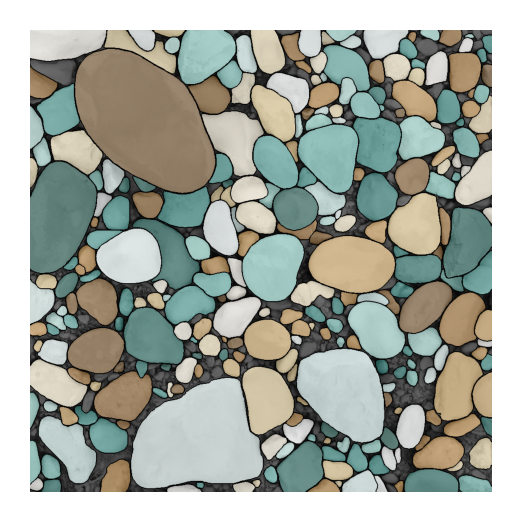

In [4]:
# Project directories
from src.visualization import show_masks


PROJECT_ROOT = Path("..").resolve()
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR_visualizations = PROJECT_ROOT / "output"

label_path = (
    DATA_DIR / "IG2" / "PP" / "test" / "predictions"
    / "PYRA_4_T0_SAM_F0_pred.tif"
)

# Output file
save_path = (
    OUTPUT_DIR_visualizations / "PYRA_4_T0_SAM-F0.png"
)

# Create output directory if it does not exist
save_path.parent.mkdir(parents=True, exist_ok=True)

show_masks(
    image_path,
    label_path,
    save_path=save_path,
    dpi=300,
    figsize=(2, 2)
)